In [24]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import random

from torch.utils.data import DataLoader, random_split, Subset

# Set random seeds for reproducibility
torch.manual_seed(42)
np.random.seed(42)
random.seed(42)

# Select GPU if available
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch Version:", torch.__version__)
print("Device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch Version: 2.11.0+cu130
Device: cuda
GPU: Tesla T4


In [25]:
transform = transforms.ToTensor()

# Load training dataset
full_train_dataset = torchvision.datasets.FashionMNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

# Load testing dataset
test_dataset = torchvision.datasets.FashionMNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

# Split training data into training and validation
train_dataset, val_dataset = random_split(
    full_train_dataset,
    [54000, 6000],
    generator=torch.Generator().manual_seed(42)
)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Testing samples:", len(test_dataset))

Training samples: 54000
Validation samples: 6000
Testing samples: 10000


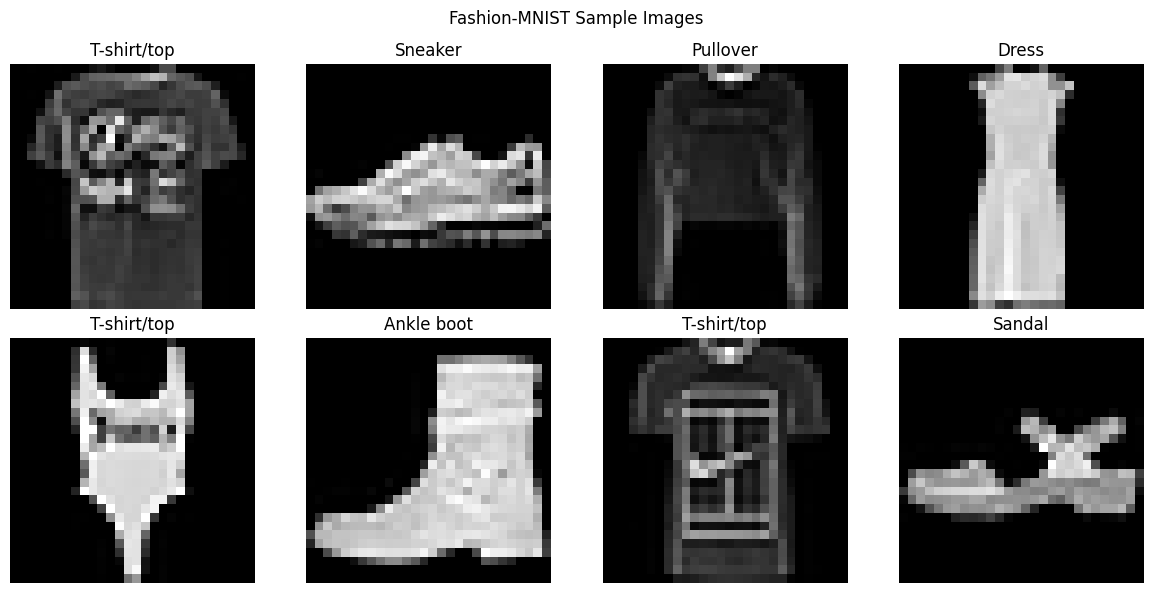

In [26]:
class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for ax in axes.flat:
    index = random.randrange(len(train_dataset))
    image, label = train_dataset[index]

    ax.imshow(image.squeeze(), cmap="gray")
    ax.set_title(class_names[label])
    ax.axis("off")

plt.suptitle("Fashion-MNIST Sample Images")
plt.tight_layout()
plt.show()

In [27]:
BATCH_SIZE = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=(DEVICE.type == "cuda")
)

val_loader = DataLoader(
    val_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=2,
    pin_memory=(DEVICE.type == "cuda")
)

test_loader = DataLoader(
    test_dataset,
    batch_size=128,
    shuffle=False,
    num_workers=2,
    pin_memory=(DEVICE.type == "cuda")
)

images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)

Image batch shape: torch.Size([64, 1, 28, 28])
Label batch shape: torch.Size([64])


In [28]:
class CNN4(nn.Module):

    def __init__(self, filters=(32, 64, 128, 256)):
        super(CNN4, self).__init__()

        self.conv1 = nn.Conv2d(
            1, filters[0], kernel_size=3, padding=1
        )

        self.conv2 = nn.Conv2d(
            filters[0], filters[1], kernel_size=3, padding=1
        )

        self.conv3 = nn.Conv2d(
            filters[1], filters[2], kernel_size=3, padding=1
        )

        self.conv4 = nn.Conv2d(
            filters[2], filters[3], kernel_size=3, padding=1
        )

        self.relu = nn.ReLU()

        self.pool = nn.MaxPool2d(
            kernel_size=2,
            stride=2
        )

        self.gap = nn.AdaptiveAvgPool2d((1, 1))

        self.fc = nn.Linear(filters[3], 10)

    def forward(self, x):

        x = self.pool(self.relu(self.conv1(x)))
        x = self.pool(self.relu(self.conv2(x)))
        x = self.pool(self.relu(self.conv3(x)))

        x = self.relu(self.conv4(x))

        x = self.gap(x)

        x = torch.flatten(x, 1)

        x = self.fc(x)

        return x

In [29]:
model = CNN4().to(DEVICE)

total_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(model)
print("\nTotal trainable parameters:", total_params)

CNN4(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv4): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu): ReLU()
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (gap): AdaptiveAvgPool2d(output_size=(1, 1))
  (fc): Linear(in_features=256, out_features=10, bias=True)
)

Total trainable parameters: 390410


In [30]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Loss function:", criterion)
print("Optimizer:", optimizer)

Loss function: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


In [31]:
EPOCHS = 5

train_losses = []
train_accuracies = []
val_accuracies = []

for epoch in range(EPOCHS):

    # Training phase
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

        predictions = outputs.argmax(dim=1)

        total += labels.size(0)
        correct += (predictions == labels).sum().item()

    epoch_loss = running_loss / len(train_loader)
    train_accuracy = 100 * correct / total

    train_losses.append(epoch_loss)
    train_accuracies.append(train_accuracy)

    # Validation phase
    model.eval()

    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            outputs = model(images)

            predictions = outputs.argmax(dim=1)

            val_total += labels.size(0)
            val_correct += (predictions == labels).sum().item()

    val_accuracy = 100 * val_correct / val_total

    val_accuracies.append(val_accuracy)

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Loss: {epoch_loss:.4f} "
        f"Train Accuracy: {train_accuracy:.2f}% "
        f"Validation Accuracy: {val_accuracy:.2f}%"
    )

Epoch [1/5] Loss: 0.6610 Train Accuracy: 75.36% Validation Accuracy: 83.27%
Epoch [2/5] Loss: 0.3814 Train Accuracy: 86.14% Validation Accuracy: 85.63%
Epoch [3/5] Loss: 0.3114 Train Accuracy: 88.62% Validation Accuracy: 88.17%
Epoch [4/5] Loss: 0.2743 Train Accuracy: 89.81% Validation Accuracy: 89.37%
Epoch [5/5] Loss: 0.2498 Train Accuracy: 90.79% Validation Accuracy: 89.73%


In [32]:
model.eval()

test_correct = 0
test_total = 0

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        outputs = model(images)

        predictions = outputs.argmax(dim=1)

        test_total += labels.size(0)

        test_correct += (
            predictions == labels
        ).sum().item()

test_accuracy = 100 * test_correct / test_total

print(f"Test Accuracy: {test_accuracy:.2f}%")

Test Accuracy: 89.86%


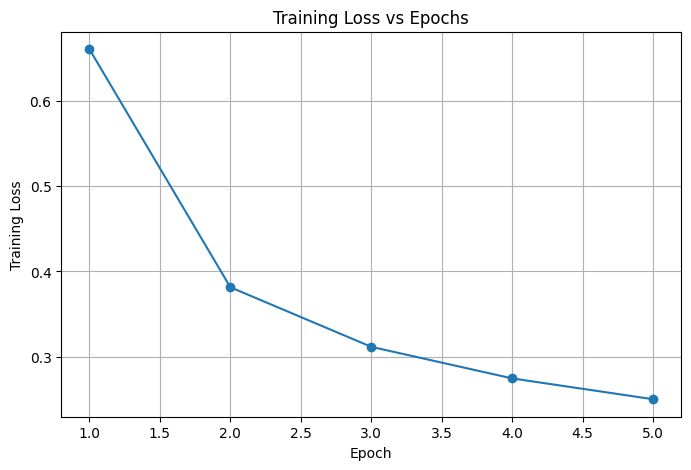

In [33]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, EPOCHS + 1),
    train_losses,
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Training Loss vs Epochs")
plt.grid(True)
plt.show()

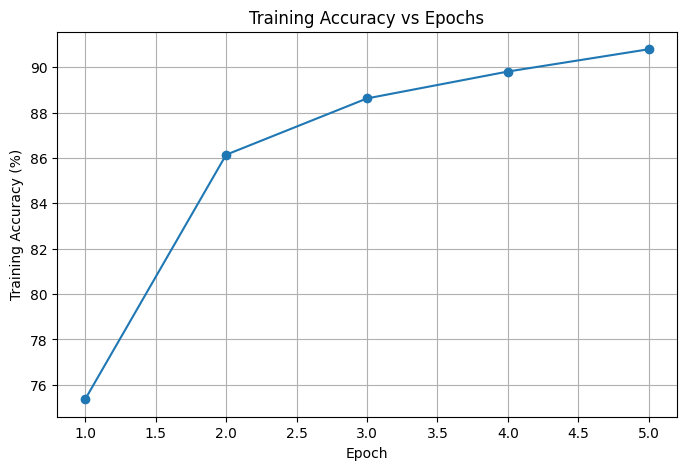

In [34]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, EPOCHS + 1),
    train_accuracies,
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Training Accuracy (%)")
plt.title("Training Accuracy vs Epochs")
plt.grid(True)
plt.show()

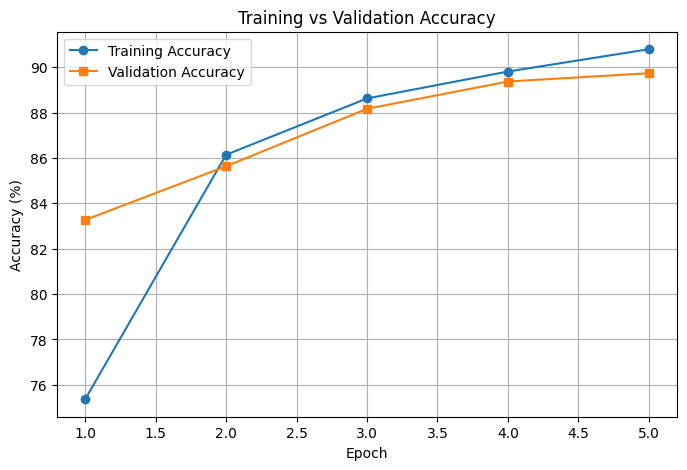

In [35]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, EPOCHS + 1),
    train_accuracies,
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    range(1, EPOCHS + 1),
    val_accuracies,
    marker="s",
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

In [36]:
def run_experiment(
    name,
    optimizer_name="Adam",
    lr=0.001,
    batch_size=64,
    filters=(32, 64, 128, 256),
    epochs=3
):

    print(f"\n{'=' * 50}")
    print("Experiment:", name)
    print("Optimizer:", optimizer_name)
    print("Learning rate:", lr)
    print("Batch size:", batch_size)
    print("Filters:", filters)
    print("=" * 50)

    model_exp = CNN4(filters=filters).to(DEVICE)

    train_loader_exp = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=2,
        pin_memory=(DEVICE.type == "cuda")
    )

    val_loader_exp = DataLoader(
        val_dataset,
        batch_size=128,
        shuffle=False,
        num_workers=2,
        pin_memory=(DEVICE.type == "cuda")
    )

    criterion_exp = nn.CrossEntropyLoss()

    if optimizer_name == "Adam":

        optimizer_exp = optim.Adam(
            model_exp.parameters(),
            lr=lr
        )

    elif optimizer_name == "SGD":

        optimizer_exp = optim.SGD(
            model_exp.parameters(),
            lr=lr
        )

    elif optimizer_name == "RMSprop":

        optimizer_exp = optim.RMSprop(
            model_exp.parameters(),
            lr=lr
        )

    else:
        raise ValueError("Unsupported optimizer")

    history = []

    for epoch in range(epochs):

        # Training
        model_exp.train()

        running_loss = 0.0
        correct = 0
        total = 0

        for images, labels in train_loader_exp:

            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            optimizer_exp.zero_grad()

            outputs = model_exp(images)

            loss = criterion_exp(outputs, labels)

            loss.backward()

            optimizer_exp.step()

            running_loss += loss.item()

            predictions = outputs.argmax(dim=1)

            total += labels.size(0)
            correct += (predictions == labels).sum().item()

        train_accuracy = 100 * correct / total

        # Validation
        model_exp.eval()

        val_correct = 0
        val_total = 0

        with torch.no_grad():

            for images, labels in val_loader_exp:

                images = images.to(DEVICE, non_blocking=True)
                labels = labels.to(DEVICE, non_blocking=True)

                outputs = model_exp(images)

                predictions = outputs.argmax(dim=1)

                val_total += labels.size(0)

                val_correct += (
                    predictions == labels
                ).sum().item()

        val_accuracy = 100 * val_correct / val_total

        avg_loss = running_loss / len(train_loader_exp)

        history.append({
            "Epoch": epoch + 1,
            "Loss": avg_loss,
            "Train Accuracy": train_accuracy,
            "Validation Accuracy": val_accuracy
        })

        print(
            f"Epoch {epoch+1}/{epochs} | "
            f"Loss: {avg_loss:.4f} | "
            f"Train Accuracy: {train_accuracy:.2f}% | "
            f"Validation Accuracy: {val_accuracy:.2f}%"
        )

    params = sum(
        p.numel()
        for p in model_exp.parameters()
        if p.requires_grad
    )

    return {
        "Experiment": name,
        "Optimizer": optimizer_name,
        "Learning Rate": lr,
        "Batch Size": batch_size,
        "Filters": str(filters),
        "Parameters": params,
        "Train Accuracy (%)": round(train_accuracy, 2),
        "Validation Accuracy (%)": round(val_accuracy, 2),
        "Model": model_exp,
        "History": history
    }

In [37]:
experiments = [
    {
        "name": "Baseline Adam",
        "optimizer_name": "Adam",
        "lr": 0.001,
        "batch_size": 64
    },
    {
        "name": "SGD Optimizer",
        "optimizer_name": "SGD",
        "lr": 0.01,
        "batch_size": 64
    },
    {
        "name": "RMSprop Optimizer",
        "optimizer_name": "RMSprop",
        "lr": 0.001,
        "batch_size": 64
    },
    {
        "name": "Lower Learning Rate",
        "optimizer_name": "Adam",
        "lr": 0.0001,
        "batch_size": 64
    },
    {
        "name": "Larger Batch Size",
        "optimizer_name": "Adam",
        "lr": 0.001,
        "batch_size": 128
    }
]

results = []

for exp in experiments:

    result = run_experiment(
        name=exp["name"],
        optimizer_name=exp["optimizer_name"],
        lr=exp["lr"],
        batch_size=exp["batch_size"],
        filters=(32, 64, 128, 256),
        epochs=3
    )

    results.append(result)


Experiment: Baseline Adam
Optimizer: Adam
Learning rate: 0.001
Batch size: 64
Filters: (32, 64, 128, 256)
Epoch 1/3 | Loss: 0.6470 | Train Accuracy: 75.80% | Validation Accuracy: 83.75%
Epoch 2/3 | Loss: 0.3742 | Train Accuracy: 86.36% | Validation Accuracy: 86.97%
Epoch 3/3 | Loss: 0.3081 | Train Accuracy: 88.71% | Validation Accuracy: 88.00%

Experiment: SGD Optimizer
Optimizer: SGD
Learning rate: 0.01
Batch size: 64
Filters: (32, 64, 128, 256)
Epoch 1/3 | Loss: 2.2878 | Train Accuracy: 16.84% | Validation Accuracy: 10.78%
Epoch 2/3 | Loss: 1.6051 | Train Accuracy: 43.53% | Validation Accuracy: 54.43%
Epoch 3/3 | Loss: 0.9210 | Train Accuracy: 64.68% | Validation Accuracy: 61.68%

Experiment: RMSprop Optimizer
Optimizer: RMSprop
Learning rate: 0.001
Batch size: 64
Filters: (32, 64, 128, 256)
Epoch 1/3 | Loss: 0.6841 | Train Accuracy: 73.99% | Validation Accuracy: 85.05%
Epoch 2/3 | Loss: 0.3719 | Train Accuracy: 86.10% | Validation Accuracy: 87.82%
Epoch 3/3 | Loss: 0.3029 | Train A

In [46]:
# Display all experiment results
results_df = pd.DataFrame([
    {
        "Experiment": r["Experiment"],
        "Optimizer": r["Optimizer"],
        "Learning Rate": r["Learning Rate"],
        "Batch Size": r["Batch Size"],
        "Parameters": r["Parameters"],
        "Training Accuracy (%)": r["Train Accuracy (%)"],
        "Validation Accuracy (%)": r["Validation Accuracy (%)"]
    }
    for r in results
])

display(results_df)

# Select winner based on training accuracy
best_result = max(
    results,
    key=lambda r: r["Train Accuracy (%)"]
)

best_model = best_result["Model"]

print("\n" + "=" * 45)
print("BEST CNN CONFIGURATION")
print("=" * 45)

print("Experiment:", best_result["Experiment"])
print("Optimizer:", best_result["Optimizer"])
print("Learning Rate:", best_result["Learning Rate"])
print("Batch Size:", best_result["Batch Size"])
print("Trainable Parameters:", best_result["Parameters"])

print("\nPERFORMANCE METRICS")
print("-" * 45)

print(f"Training Accuracy: {best_result['Train Accuracy (%)']:.2f}%")
print(f"Validation Accuracy: {best_result['Validation Accuracy (%)']:.2f}%")

,Experiment,Optimizer,Learning Rate,Batch Size,Parameters,Training Accuracy (%),Validation Accuracy (%)
0,Baseline Adam,Adam,0.0010,64,390410,88.71,88.00
1,SGD Optimizer,SGD,0.0100,64,390410,64.68,61.68
2,RMSprop Optimizer,RMSprop,0.0010,64,390410,88.83,88.72
3,Lower Learning Rate,Adam,0.0001,64,390410,78.54,79.70
4,Larger Batch Size,Adam,0.0010,128,390410,86.39,85.62



BEST CNN CONFIGURATION
Experiment: RMSprop Optimizer
Optimizer: RMSprop
Learning Rate: 0.001
Batch Size: 64
Trainable Parameters: 390410

PERFORMANCE METRICS
---------------------------------------------
Training Accuracy: 88.83%
Validation Accuracy: 88.72%


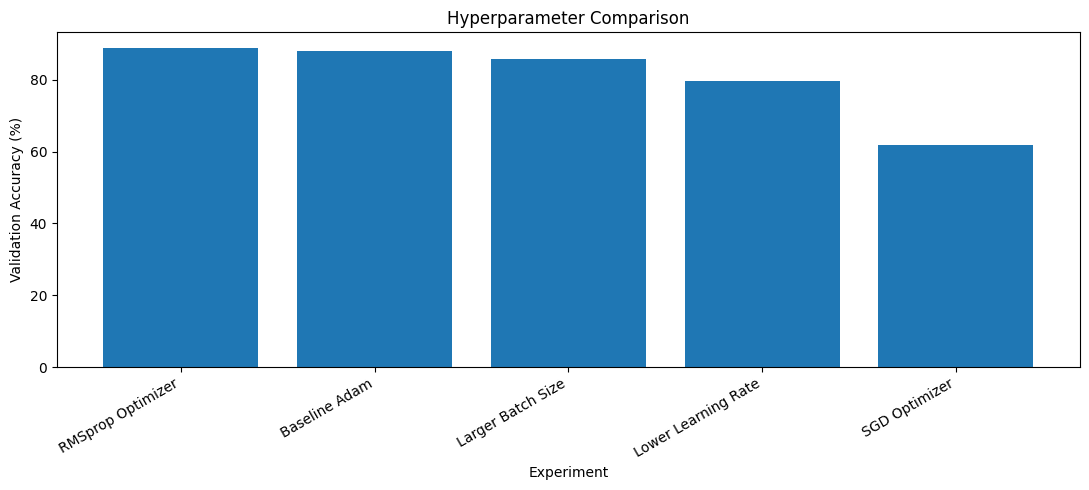

In [39]:
plt.figure(figsize=(11, 5))

plt.bar(
    results_df["Experiment"],
    results_df["Validation Accuracy (%)"]
)

plt.xlabel("Experiment")
plt.ylabel("Validation Accuracy (%)")
plt.title("Hyperparameter Comparison")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [43]:
best_result = max(
    results,
    key=lambda r: r["Validation Accuracy (%)"]
)

best_model = best_result["Model"]

print("=" * 45)
print("BEST CNN CONFIGURATION")
print("=" * 45)

print("Experiment:", best_result["Experiment"])
print("Optimizer:", best_result["Optimizer"])
print("Learning Rate:", best_result["Learning Rate"])
print("Batch Size:", best_result["Batch Size"])
print("Trainable Parameters:", best_result["Parameters"])

print("\nPERFORMANCE METRICS")
print("-" * 45)

print(
    f"Training Accuracy: "
    f"{best_result['Train Accuracy (%)']:.2f}%"
)

print(
    f"Validation Accuracy: "
    f"{best_result['Validation Accuracy (%)']:.2f}%"
)

BEST CNN CONFIGURATION
Experiment: RMSprop Optimizer
Optimizer: RMSprop
Learning Rate: 0.001
Batch Size: 64
Trainable Parameters: 390410

PERFORMANCE METRICS
---------------------------------------------
Training Accuracy: 88.83%
Validation Accuracy: 88.72%


In [44]:
best_model.eval()

test_correct = 0
test_total = 0

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        outputs = best_model(images)
        predictions = outputs.argmax(dim=1)

        test_total += labels.size(0)
        test_correct += (predictions == labels).sum().item()

final_test_accuracy = 100 * test_correct / test_total

print(
    f"Test Accuracy: {final_test_accuracy:.2f}%"
)

print("=" * 45)

Test Accuracy: 87.85%


In [45]:
print("ALL EXPERIMENT RESULTS")
print("=" * 60)

for result in results:
    print(f"\nExperiment: {result['Experiment']}")
    print(f"Optimizer: {result['Optimizer']}")
    print(f"Training Accuracy: {result['Train Accuracy (%)']}%")
    print(f"Validation Accuracy: {result['Validation Accuracy (%)']}%")

print("\n" + "=" * 60)

ALL EXPERIMENT RESULTS

Experiment: Baseline Adam
Optimizer: Adam
Training Accuracy: 88.71%
Validation Accuracy: 88.0%

Experiment: SGD Optimizer
Optimizer: SGD
Training Accuracy: 64.68%
Validation Accuracy: 61.68%

Experiment: RMSprop Optimizer
Optimizer: RMSprop
Training Accuracy: 88.83%
Validation Accuracy: 88.72%

Experiment: Lower Learning Rate
Optimizer: Adam
Training Accuracy: 78.54%
Validation Accuracy: 79.7%

Experiment: Larger Batch Size
Optimizer: Adam
Training Accuracy: 86.39%
Validation Accuracy: 85.62%



In [47]:
class CNN2(nn.Module):

    def __init__(self):
        super(CNN2, self).__init__()

        # First convolutional layer
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)

        # Second convolutional layer
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)

        self.relu = nn.ReLU()
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        # Global average pooling
        self.gap = nn.AdaptiveAvgPool2d((1, 1))

        # Fully connected output layer
        self.fc = nn.Linear(64, 10)

    def forward(self, x):

        x = self.pool(self.relu(self.conv1(x)))  # 14 × 14 × 32

        x = self.pool(self.relu(self.conv2(x)))  # 7 × 7 × 64

        x = self.gap(x)                          # 1 × 1 × 64

        x = torch.flatten(x, 1)                  # 64 features

        x = self.fc(x)                           # 10 classes

        return x

In [48]:
# Create both models
model4 = CNN4().to(DEVICE)
model2 = CNN2().to(DEVICE)

# Count trainable parameters
params4 = sum(
    p.numel() for p in model4.parameters()
    if p.requires_grad
)

params2 = sum(
    p.numel() for p in model2.parameters()
    if p.requires_grad
)

print("4-Layer CNN Parameters:", params4)
print("2-Layer CNN Parameters:", params2)

4-Layer CNN Parameters: 390410
2-Layer CNN Parameters: 19466


In [49]:
def train_cnn(model, train_loader, val_loader, epochs=5):

    model = model.to(DEVICE)

    criterion = nn.CrossEntropyLoss()

    optimizer = optim.Adam(
        model.parameters(),
        lr=0.001
    )

    train_losses = []
    train_accuracies = []
    val_accuracies = []

    for epoch in range(epochs):

        # Training
        model.train()

        running_loss = 0.0
        correct = 0
        total = 0

        for images, labels in train_loader:

            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            optimizer.zero_grad()

            outputs = model(images)

            loss = criterion(outputs, labels)

            loss.backward()

            optimizer.step()

            running_loss += loss.item()

            predictions = outputs.argmax(dim=1)

            total += labels.size(0)
            correct += (predictions == labels).sum().item()

        train_accuracy = 100 * correct / total
        epoch_loss = running_loss / len(train_loader)

        train_losses.append(epoch_loss)
        train_accuracies.append(train_accuracy)

        # Validation
        model.eval()

        val_correct = 0
        val_total = 0

        with torch.no_grad():

            for images, labels in val_loader:

                images = images.to(DEVICE)
                labels = labels.to(DEVICE)

                outputs = model(images)

                predictions = outputs.argmax(dim=1)

                val_total += labels.size(0)

                val_correct += (
                    predictions == labels
                ).sum().item()

        val_accuracy = 100 * val_correct / val_total

        val_accuracies.append(val_accuracy)

        print(
            f"Epoch {epoch+1}/{epochs} | "
            f"Loss: {epoch_loss:.4f} | "
            f"Train Accuracy: {train_accuracy:.2f}% | "
            f"Validation Accuracy: {val_accuracy:.2f}%"
        )

    return model, train_losses, train_accuracies, val_accuracies

In [50]:
model4 = CNN4().to(DEVICE)

model4, loss4, train_acc4, val_acc4 = train_cnn(
    model4,
    train_loader,
    val_loader,
    epochs=5
)

Epoch 1/5 | Loss: 0.6566 | Train Accuracy: 75.47% | Validation Accuracy: 82.72%
Epoch 2/5 | Loss: 0.3794 | Train Accuracy: 86.09% | Validation Accuracy: 87.30%
Epoch 3/5 | Loss: 0.3105 | Train Accuracy: 88.51% | Validation Accuracy: 88.87%
Epoch 4/5 | Loss: 0.2745 | Train Accuracy: 89.98% | Validation Accuracy: 89.90%
Epoch 5/5 | Loss: 0.2486 | Train Accuracy: 90.74% | Validation Accuracy: 90.38%


In [51]:
model2 = CNN2().to(DEVICE)

model2, loss2, train_acc2, val_acc2 = train_cnn(
    model2,
    train_loader,
    val_loader,
    epochs=5
)

Epoch 1/5 | Loss: 1.3113 | Train Accuracy: 54.08% | Validation Accuracy: 66.45%
Epoch 2/5 | Loss: 0.8277 | Train Accuracy: 70.94% | Validation Accuracy: 73.73%
Epoch 3/5 | Loss: 0.7158 | Train Accuracy: 74.74% | Validation Accuracy: 74.85%
Epoch 4/5 | Loss: 0.6597 | Train Accuracy: 76.67% | Validation Accuracy: 77.45%
Epoch 5/5 | Loss: 0.6217 | Train Accuracy: 78.07% | Validation Accuracy: 78.47%


In [52]:
comparison = pd.DataFrame({
    "CNN Architecture": [
        "2 Convolutional Layers",
        "4 Convolutional Layers"
    ],
    "Parameters": [
        params2,
        params4
    ],
    "Training Accuracy (%)": [
        train_acc2[-1],
        train_acc4[-1]
    ],
    "Validation Accuracy (%)": [
        val_acc2[-1],
        val_acc4[-1]
    ]
})

display(comparison)

,CNN Architecture,Parameters,Training Accuracy (%),Validation Accuracy (%)
0,2 Convolutional Layers,19466,78.072222,78.466667
1,4 Convolutional Layers,390410,90.740741,90.383333


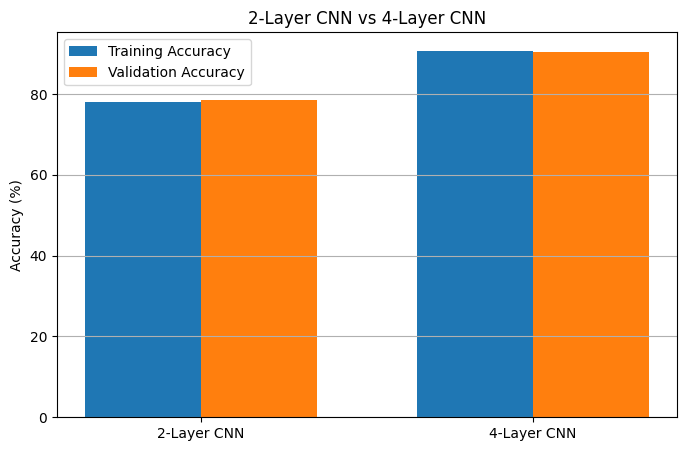

In [53]:
architectures = [
    "2-Layer CNN",
    "4-Layer CNN"
]

training_accuracy = [
    train_acc2[-1],
    train_acc4[-1]
]

validation_accuracy = [
    val_acc2[-1],
    val_acc4[-1]
]

x = np.arange(len(architectures))
width = 0.35

plt.figure(figsize=(8, 5))

plt.bar(
    x - width/2,
    training_accuracy,
    width,
    label="Training Accuracy"
)

plt.bar(
    x + width/2,
    validation_accuracy,
    width,
    label="Validation Accuracy"
)

plt.xticks(x, architectures)
plt.ylabel("Accuracy (%)")
plt.title("2-Layer CNN vs 4-Layer CNN")
plt.legend()
plt.grid(axis="y")
plt.show()

In [54]:
def evaluate_model(model, test_loader):

    model.eval()

    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in test_loader:

            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            outputs = model(images)

            predictions = outputs.argmax(dim=1)

            total += labels.size(0)

            correct += (
                predictions == labels
            ).sum().item()

    return 100 * correct / total


test_acc2 = evaluate_model(model2, test_loader)
test_acc4 = evaluate_model(model4, test_loader)

print(f"2-Layer CNN Test Accuracy: {test_acc2:.2f}%")
print(f"4-Layer CNN Test Accuracy: {test_acc4:.2f}%")

2-Layer CNN Test Accuracy: 79.05%
4-Layer CNN Test Accuracy: 90.00%


In [57]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix, classification_report

In [58]:
# Fashion-MNIST class names
class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

# Use your selected trained model
best_model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        outputs = best_model(images)

        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

all_predictions = np.array(all_predictions)
all_labels = np.array(all_labels)

print("Total test images:", len(all_labels))
print("Total predictions:", len(all_predictions))

test_accuracy = 100 * np.mean(all_predictions == all_labels)

print(f"Test Accuracy: {test_accuracy:.2f}%")

Total test images: 10000
Total predictions: 10000
Test Accuracy: 87.85%


In [59]:
cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=list(range(10))
)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[686   0  13  89  10   1 194   0   7   0]
 [  0 975   0  18   5   0   2   0   0   0]
 [  8   1 778  11 117   0  85   0   0   0]
 [  4   6   5 933  26   0  25   0   1   0]
 [  0   0  34  38 890   0  38   0   0   0]
 [  0   0   0   2   0 967   0  18   0  13]
 [ 58   2  65  69 133   0 667   0   6   0]
 [  0   0   0   0   0   7   0 948   0  45]
 [  1   0   0   5   5   1   8   4 975   1]
 [  0   0   0   0   0   3   1  29   1 966]]


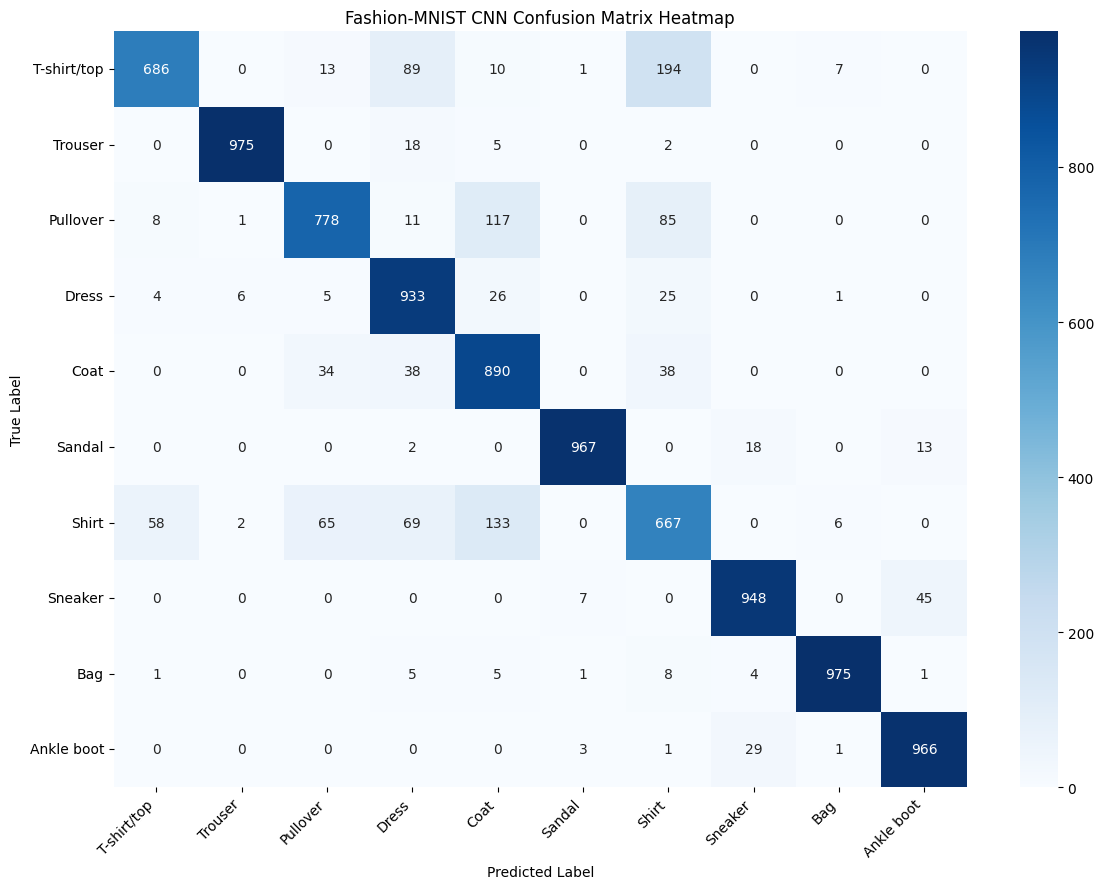

In [60]:
plt.figure(figsize=(12, 9))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Fashion-MNIST CNN Confusion Matrix Heatmap")

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

In [61]:
print(
    classification_report(
        all_labels,
        all_predictions,
        labels=list(range(10)),
        target_names=class_names,
        zero_division=0
    )
)

              precision    recall  f1-score   support

 T-shirt/top       0.91      0.69      0.78      1000
     Trouser       0.99      0.97      0.98      1000
    Pullover       0.87      0.78      0.82      1000
       Dress       0.80      0.93      0.86      1000
        Coat       0.75      0.89      0.81      1000
      Sandal       0.99      0.97      0.98      1000
       Shirt       0.65      0.67      0.66      1000
     Sneaker       0.95      0.95      0.95      1000
         Bag       0.98      0.97      0.98      1000
  Ankle boot       0.94      0.97      0.95      1000

    accuracy                           0.88     10000
   macro avg       0.88      0.88      0.88     10000
weighted avg       0.88      0.88      0.88     10000



In [62]:
print("=" * 45)
print("FASHION-MNIST CNN RESULTS")
print("=" * 45)

print("Dataset: Fashion-MNIST")
print("Architecture: Four-Layer CNN")
print("Number of Classes: 10")
print("Test Images:", len(all_labels))
print(f"Test Accuracy: {test_accuracy:.2f}%")

print("=" * 45)

FASHION-MNIST CNN RESULTS
Dataset: Fashion-MNIST
Architecture: Four-Layer CNN
Number of Classes: 10
Test Images: 10000
Test Accuracy: 87.85%


In [64]:
import torch
import torchvision
import torchvision.transforms as transforms

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

train_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

print("CIFAR-10 downloaded successfully!")

 33%|███▎      | 55.6M/170M [10:49<22:20, 85.7kB/s]


KeyboardInterrupt: 

In [ ]:
BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=(DEVICE.type == "cuda")
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=(DEVICE.type == "cuda")
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=(DEVICE.type == "cuda")
)

images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)

In [65]:
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

from torch.utils.data import DataLoader
from torchvision.models import resnet18, ResNet18_Weights
from sklearn.metrics import confusion_matrix, classification_report

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

Device: cuda


In [66]:
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

train_dataset = torchvision.datasets.FashionMNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = torchvision.datasets.FashionMNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

train_loader = DataLoader(
    train_dataset, batch_size=64, shuffle=True, num_workers=2
)

test_loader = DataLoader(
    test_dataset, batch_size=64, shuffle=False, num_workers=2
)

print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))

Training images: 60000
Testing images: 10000


In [67]:
weights = ResNet18_Weights.DEFAULT
model = resnet18(weights=weights)

# Freeze pretrained layers
for param in model.parameters():
    param.requires_grad = False

# Replace the final classification layer
model.fc = nn.Linear(model.fc.in_features, 10)

model = model.to(DEVICE)

print(model.fc)
print("Pretrained ResNet-18 loaded successfully!")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 122MB/s]


Linear(in_features=512, out_features=10, bias=True)
Pretrained ResNet-18 loaded successfully!


In [68]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.fc.parameters(),
    lr=0.001
)

epochs = 3

train_losses = []
train_accuracies = []

for epoch in range(epochs):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        total += labels.size(0)
        correct += (predictions == labels).sum().item()

    epoch_loss = running_loss / total
    epoch_accuracy = 100 * correct / total

    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_accuracy)

    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Loss: {epoch_loss:.4f} "
        f"Accuracy: {epoch_accuracy:.2f}%"
    )

Epoch [1/3] Loss: 0.5928 Accuracy: 80.51%
Epoch [2/3] Loss: 0.4287 Accuracy: 84.76%
Epoch [3/3] Loss: 0.4034 Accuracy: 85.56%


In [69]:
model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(DEVICE)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())

all_predictions = np.array(all_predictions)
all_labels = np.array(all_labels)

test_accuracy = 100 * np.mean(all_predictions == all_labels)

print(f"Test Accuracy: {test_accuracy:.2f}%")

Test Accuracy: 85.89%


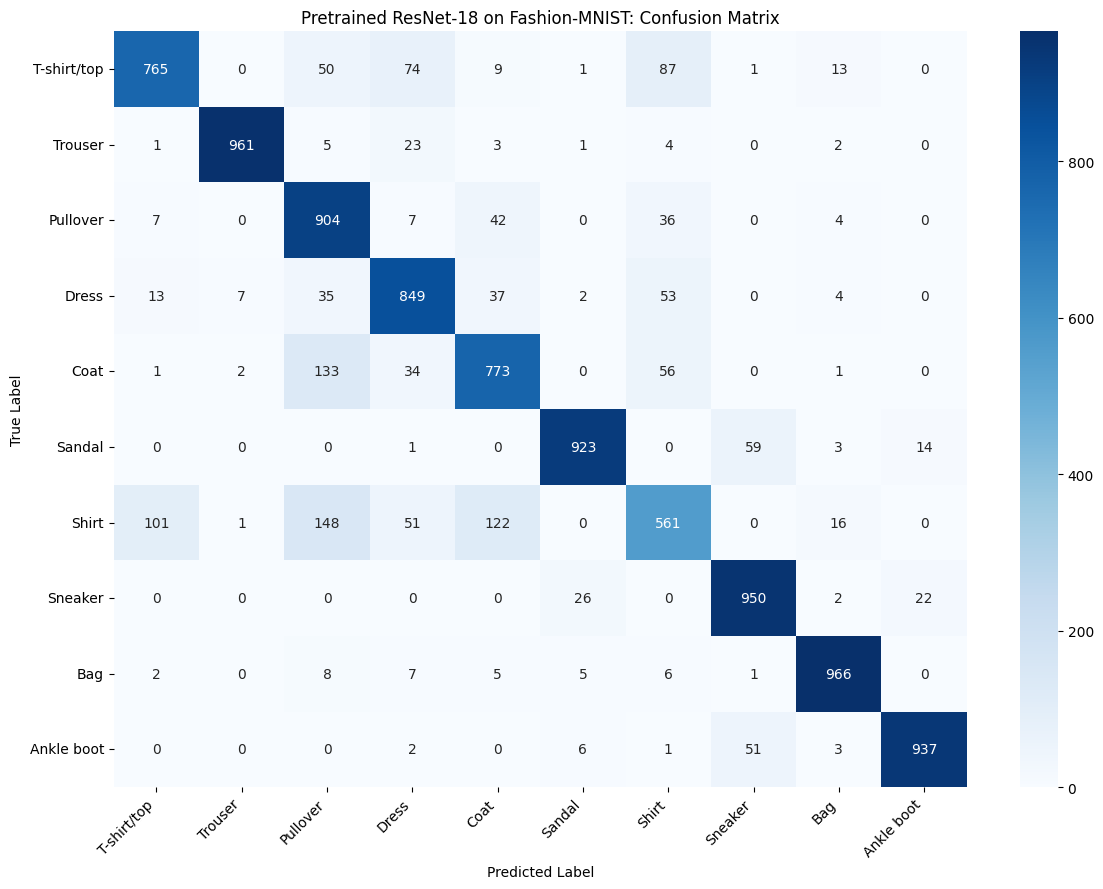

In [70]:
class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=list(range(10))
)

plt.figure(figsize=(12, 9))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Pretrained ResNet-18 on Fashion-MNIST: Confusion Matrix")

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [71]:
print(
    classification_report(
        all_labels,
        all_predictions,
        target_names=class_names,
        zero_division=0
    )
)

              precision    recall  f1-score   support

 T-shirt/top       0.86      0.77      0.81      1000
     Trouser       0.99      0.96      0.98      1000
    Pullover       0.70      0.90      0.79      1000
       Dress       0.81      0.85      0.83      1000
        Coat       0.78      0.77      0.78      1000
      Sandal       0.96      0.92      0.94      1000
       Shirt       0.70      0.56      0.62      1000
     Sneaker       0.89      0.95      0.92      1000
         Bag       0.95      0.97      0.96      1000
  Ankle boot       0.96      0.94      0.95      1000

    accuracy                           0.86     10000
   macro avg       0.86      0.86      0.86     10000
weighted avg       0.86      0.86      0.86     10000



In [72]:
from sklearn.metrics import accuracy_score, classification_report
import numpy as np
import torch

model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(DEVICE)

        outputs = model(images)
        predictions = torch.argmax(outputs, dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())

all_predictions = np.array(all_predictions)
all_labels = np.array(all_labels)

class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

accuracy = accuracy_score(all_labels, all_predictions)

print("=" * 50)
print("PRETRAINED RESNET-18 - FASHION-MNIST REPORT")
print("=" * 50)

print(f"Test Accuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:\n")

report = classification_report(
    all_labels,
    all_predictions,
    target_names=class_names,
    digits=4,
    zero_division=0
)

print(report)

PRETRAINED RESNET-18 - FASHION-MNIST REPORT
Test Accuracy: 85.89%

Classification Report:

              precision    recall  f1-score   support

 T-shirt/top     0.8596    0.7650    0.8095      1000
     Trouser     0.9897    0.9610    0.9751      1000
    Pullover     0.7046    0.9040    0.7919      1000
       Dress     0.8101    0.8490    0.8291      1000
        Coat     0.7800    0.7730    0.7765      1000
      Sandal     0.9575    0.9230    0.9399      1000
       Shirt     0.6978    0.5610    0.6220      1000
     Sneaker     0.8945    0.9500    0.9214      1000
         Bag     0.9527    0.9660    0.9593      1000
  Ankle boot     0.9630    0.9370    0.9498      1000

    accuracy                         0.8589     10000
   macro avg     0.8609    0.8589    0.8575     10000
weighted avg     0.8609    0.8589    0.8575     10000



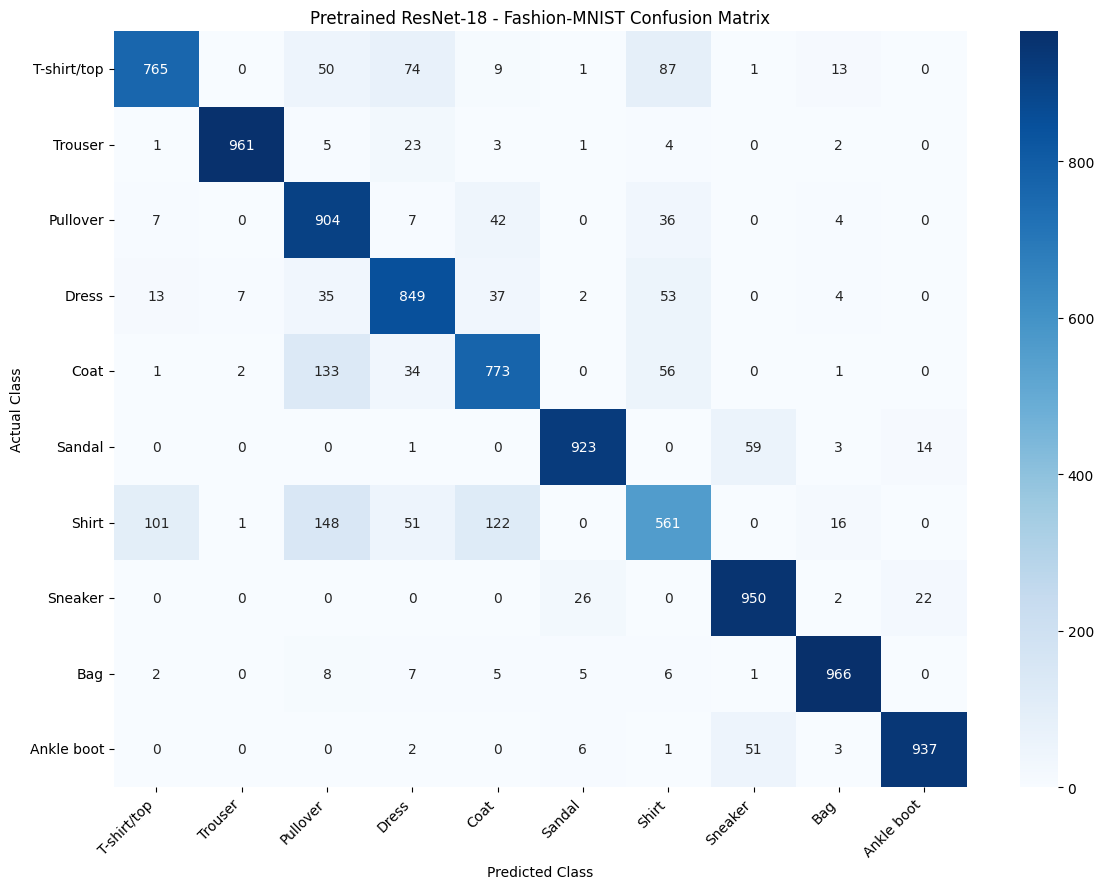

In [73]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=list(range(10))
)

plt.figure(figsize=(12, 9))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Pretrained ResNet-18 - Fashion-MNIST Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.savefig("pretrained_confusion_matrix.png", dpi=300)
plt.show()

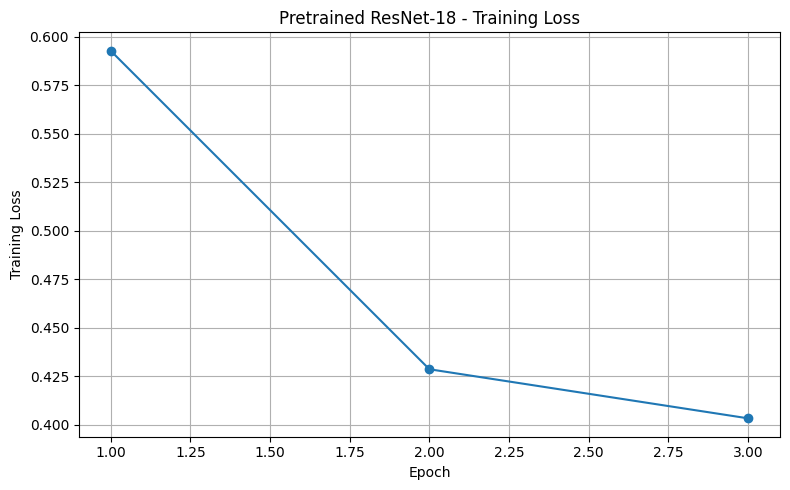

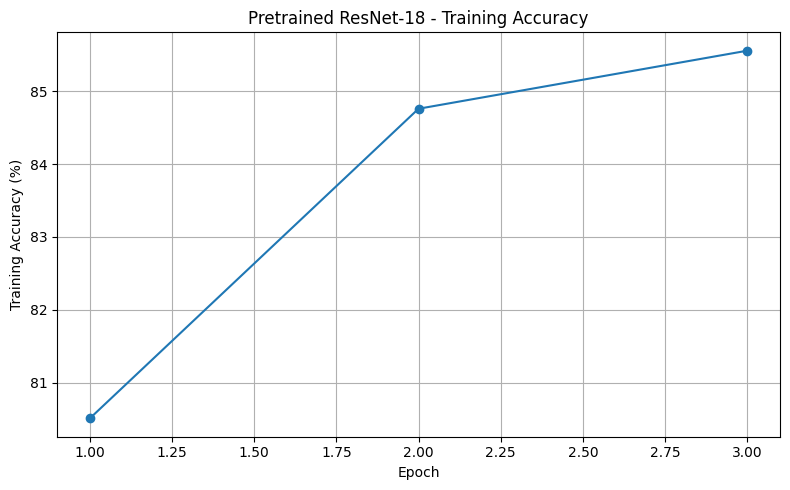

In [74]:
epochs_range = range(1, len(train_losses) + 1)

plt.figure(figsize=(8, 5))
plt.plot(epochs_range, train_losses, marker="o")
plt.title("Pretrained ResNet-18 - Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.grid(True)
plt.tight_layout()
plt.savefig("pretrained_training_loss.png", dpi=300)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(epochs_range, train_accuracies, marker="o")
plt.title("Pretrained ResNet-18 - Training Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Training Accuracy (%)")
plt.grid(True)
plt.tight_layout()
plt.savefig("pretrained_training_accuracy.png", dpi=300)
plt.show()

In [76]:
import torch
import torch.nn as nn
from torchvision.models import resnet18, ResNet18_Weights

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load ImageNet-pretrained ResNet-18
model = resnet18(weights=ResNet18_Weights.DEFAULT)

# Replace the final layer for 10 Fashion-MNIST classes
model.fc = nn.Linear(model.fc.in_features, 10)

model = model.to(DEVICE)

print("Pretrained ResNet-18 loaded!")
print("Device:", DEVICE)


Pretrained ResNet-18 loaded!
Device: cuda


In [77]:
# Freeze the entire network first
for param in model.parameters():
    param.requires_grad = False

# Unfreeze the final convolutional block
for param in model.layer4.parameters():
    param.requires_grad = True

# Unfreeze the classification head
for param in model.fc.parameters():
    param.requires_grad = True

# Display trainable parameters
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print("Total parameters:", f"{total_params:,}")
print("Trainable parameters:", f"{trainable_params:,}")
print("Frozen parameters:", f"{total_params - trainable_params:,}")

Total parameters: 11,181,642
Trainable parameters: 8,398,858
Frozen parameters: 2,782,784


In [78]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam([
    {
        "params": model.layer4.parameters(),
        "lr": 0.0001
    },
    {
        "params": model.fc.parameters(),
        "lr": 0.001
    }
])

print("Optimizer configured for fine-tuning!")

Optimizer configured for fine-tuning!


In [79]:
import matplotlib.pyplot as plt

epochs = 3

finetune_train_losses = []
finetune_train_accuracies = []

for epoch in range(epochs):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        total += labels.size(0)
        correct += (predictions == labels).sum().item()

    epoch_loss = running_loss / total
    epoch_accuracy = 100 * correct / total

    finetune_train_losses.append(epoch_loss)
    finetune_train_accuracies.append(epoch_accuracy)

    print(
        f"Epoch [{epoch + 1}/{epochs}] "
        f"Loss: {epoch_loss:.4f} | "
        f"Training Accuracy: {epoch_accuracy:.2f}%"
    )

Epoch [1/3] Loss: 0.2871 | Training Accuracy: 89.76%
Epoch [2/3] Loss: 0.1486 | Training Accuracy: 94.62%
Epoch [3/3] Loss: 0.0877 | Training Accuracy: 96.78%


In [80]:
for module in model.modules():
    if isinstance(module, nn.BatchNorm2d):
        if not any(p.requires_grad for p in module.parameters()):
            module.eval()

In [81]:
import numpy as np
from sklearn.metrics import accuracy_score, classification_report

model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(DEVICE)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())

all_predictions = np.array(all_predictions)
all_labels = np.array(all_labels)

finetune_accuracy = accuracy_score(
    all_labels,
    all_predictions
) * 100

class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

print(f"Fine-tuned Test Accuracy: {finetune_accuracy:.2f}%")

print("\nFine-tuned Classification Report:\n")

finetune_report = classification_report(
    all_labels,
    all_predictions,
    target_names=class_names,
    digits=4,
    zero_division=0
)

print(finetune_report)

Fine-tuned Test Accuracy: 92.64%

Fine-tuned Classification Report:

              precision    recall  f1-score   support

 T-shirt/top     0.8467    0.8950    0.8702      1000
     Trouser     0.9980    0.9830    0.9904      1000
    Pullover     0.8859    0.8850    0.8854      1000
       Dress     0.9222    0.9240    0.9231      1000
        Coat     0.8874    0.8980    0.8926      1000
      Sandal     0.9900    0.9930    0.9915      1000
       Shirt     0.7983    0.7560    0.7766      1000
     Sneaker     0.9555    0.9870    0.9710      1000
         Bag     0.9900    0.9860    0.9880      1000
  Ankle boot     0.9907    0.9570    0.9736      1000

    accuracy                         0.9264     10000
   macro avg     0.9265    0.9264    0.9262     10000
weighted avg     0.9265    0.9264    0.9262     10000



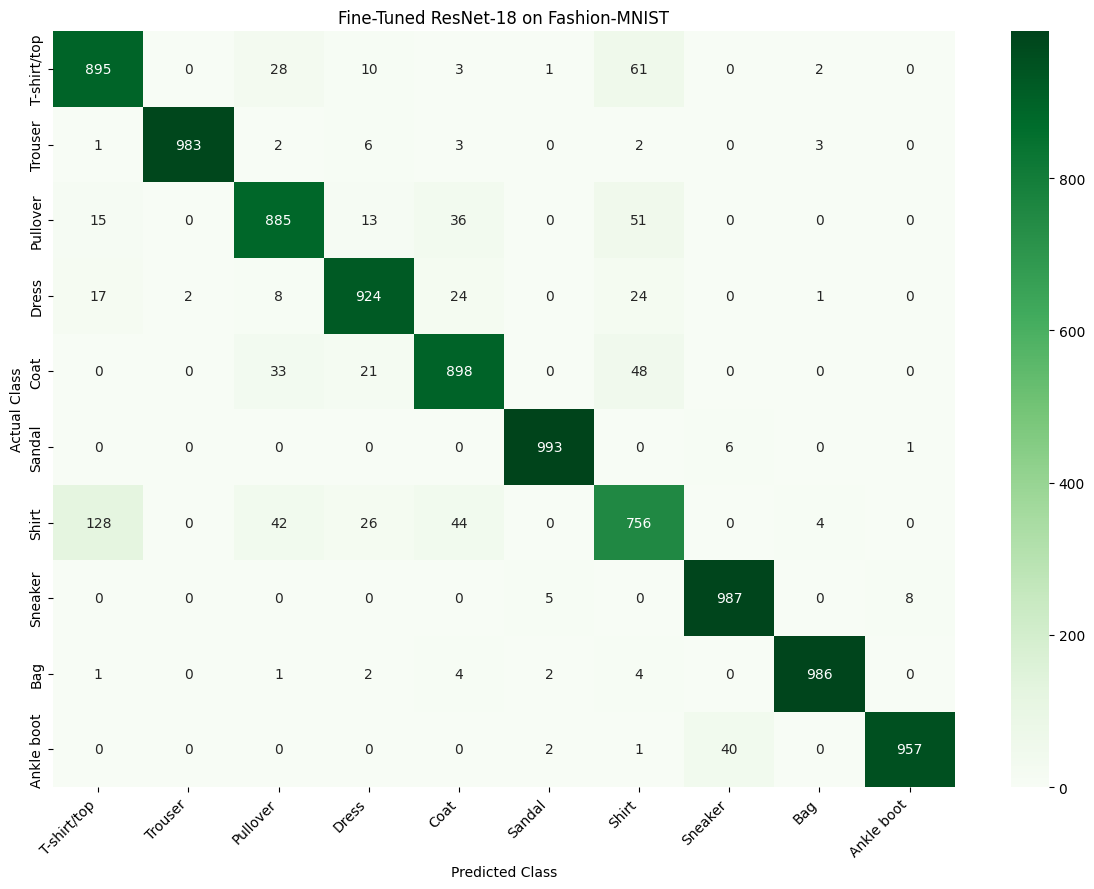

In [82]:
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=list(range(10))
)

plt.figure(figsize=(12, 9))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Fine-Tuned ResNet-18 on Fashion-MNIST")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("finetuned_resnet18_confusion_matrix.png", dpi=300)
plt.show()

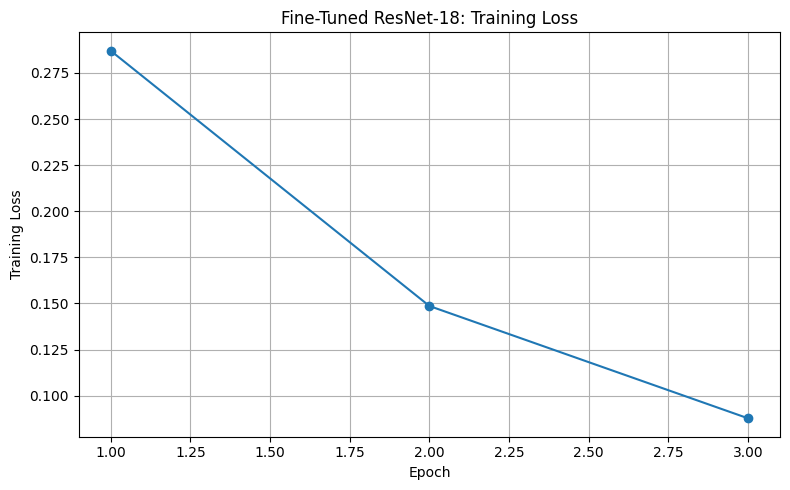

In [83]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, epochs + 1),
    finetune_train_losses,
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Fine-Tuned ResNet-18: Training Loss")
plt.grid(True)
plt.tight_layout()
plt.show()

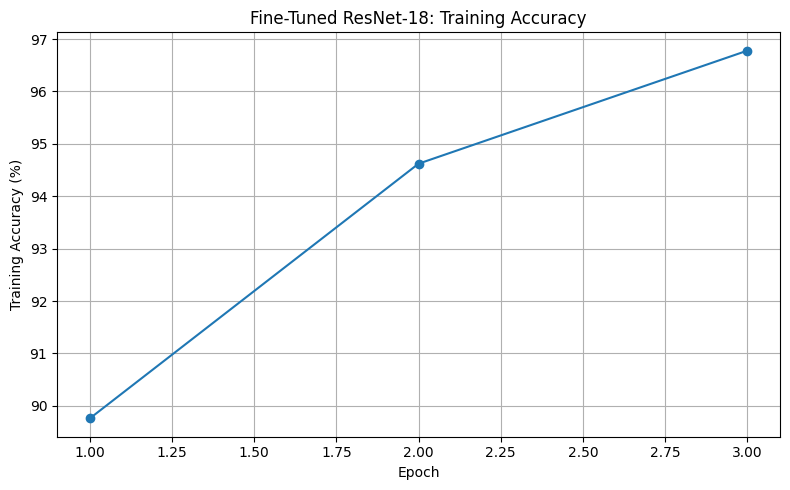

In [84]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, epochs + 1),
    finetune_train_accuracies,
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Training Accuracy (%)")
plt.title("Fine-Tuned ResNet-18: Training Accuracy")
plt.grid(True)
plt.tight_layout()
plt.show()